# Линейная алгебра. Лабораторная работа 1, осень 2025

Новоселова Владислава БЭАД256

## Часть 1. Библиотеки

В этой лабораторной работе вам понадобятся три библиотеки:

- `numpy` – основная библиотека для работы с матрицами;
- `scipy`, а точнее модуль `scipy.linalg`, содержащий множество функций линейной алгебры;
- `matplotlib` – графическая библиотека

Подключить их можно следующим образом:

In [ ]:
import numpy as np

import scipy.linalg as sla

import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
A = np.array([[1, 2, 3], [4, 5, 6]])

print(A)
print(A.shape)

[[1 2 3]
 [4 5 6]]
(2, 3)


**Задание 1.1 [0.2 балла за каждый пункт]** В качестве первого задания мы попросим вас отыскать соответствующие функции в библиотеке и сделать следующее:

- создайте нулевую матрицу $Z$ размера $3\times4$;

- создайте диагональную матрицу $5\times5$ с диагональными элементами 1, 2, 3, 4 и 5;

- найдите её след (не силою мысли, а с помощью библиотечных функций, конечно);

- найдите обратную к ней матрицу;

- сгенерируйте случайную матрицу $X$ размера $4\times5$;

- найдите определитель подматрицы матрицы $X$, расположенной на пересечении 2-й и 3-й строк и 1-го и 2-го столбцов; считаем, что строки и столбцы нумеруются с единицы (используйте slicing!). Такой определитель называется **минором** матрицы $X$;

- найдите произведение $X^TX$.

Пожалуйста, каждый пункт делайте в новом блоке и не забывайте распечатывать результаты.

In [30]:
z = np.zeros((3, 4))
print(z)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [31]:
d = np.diag([1,2,3,4,5])
print(d)

[[1 0 0 0 0]
 [0 2 0 0 0]
 [0 0 3 0 0]
 [0 0 0 4 0]
 [0 0 0 0 5]]


In [32]:
tr = np.trace(d)
print(tr)

15


In [33]:
np.linalg.inv(d)

array([[1.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.5       , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.33333333, 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.25      , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.2       ]])

In [34]:
x = np.random.randint(0, 10, [4, 5])
print(x)

[[2 5 8 1 0]
 [1 0 8 3 2]
 [7 2 8 3 1]
 [6 7 3 1 6]]


In [35]:
xo = x[1:3, 0:2]
opr = np.linalg.det(xo)
print(opr)

1.9999999999999998


In [36]:
xt = np.transpose(x)
print(np.dot(xt, x))

[[ 90  66  98  32  45]
 [ 66  78  77  18  44]
 [ 98  77 201  59  42]
 [ 32  18  59  20  15]
 [ 45  44  42  15  41]]


## Часть 2. Время

Питон мотивирует пользоваться библиотечными функциями, когда они доступны, а не писать собственные. Библиотечные функции основаны на современных алгоритмах, обычно пишутся на более эффективных языках, таких как C++ или Fortran, а кроме того, оптимизированы для работы на многопроцессорных устройствах, так что обогнать эти решения просто так вы не сможете.

**Задание 2.1 [1 балл]**
Мы предлагаем вам убедиться в этом самим. Напишите функцию `my_det`, которая вычисляла бы определитель матрицы с помощью элементарных преобразований над строками. Функция должна выкидывать `ValueError` в случаях, если матрица не является квадратной.

In [37]:
def my_det(X):
    A = np.array(X, dtype=float)
    if A.ndim != 2 or A.shape[0] != A.shape[1]:
        raise ValueError
    n = A.shape[0]
    det = 1

    for i in range(n):
        p = i + np.argmax(np.abs(A[i:, i]))
        if A[p, i] == 0:
            return 0

        if p != i:
            A[[i, p]] = A[[p, i]]
            det *= -1
        det *= A[i, i]

        for j in range(i + 1, n):
            fac = A[j, i] / A[i, i]
            A[j] -= fac * A[i]
    return det

Простая проверка:

In [38]:
# Запустите этот блок кода
X = np.array([[0,0,1], [0,1,0], [1,0,0]])
print(my_det(X))

-1.0


На случай, если нам просто повезло с этой матрицей, имеет смысл написать чуть более хитрые тесты. Мы сгенерируем несколько случайных матриц $50\times50$ с помощью функции `numpy.random.rand` и сравним ответ, выдаваемый нашей функцией, с настоящим определителем (результатом работы библиотечной функции `scipy.linalg.det`):

In [39]:
# Запустите этот блок кода
for _ in range(50):
    X = np.random.rand(50, 50)
    if np.abs(my_det(X) - sla.det(X)) > 1e-6:
        print('FAILED')

Если вы ни разу не получили `FAILED`, то ваша функция работает правильно.

Теперь давайте сравним скорость работы вашей функции и библиотечной функции `scipy.linalg.det`. В Питоне есть несколько способов измерения времени; мы воспользуемся декоратором `%timeit`. Будучи написан перед функцией, он запускает её некоторое количество раз, выбирает три случайных запуска и возвращает длительность самого быстрого из них. Модификатор `-o` между декоратором и функцией позволяет сохранять результаты работы декоратора в переменную.

Приготовьтесь, что следующий блок может работать сравнительно долго.

14.7 µs ± 2.91 µs per loop (mean ± std. dev. of 7 runs, 100000 loops each)
232 µs ± 10.3 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)
129 µs ± 32.9 µs per loop (mean ± std. dev. of 7 runs, 10000 loops each)
17.8 ms ± 3.88 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)
36.9 ms ± 2.98 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


/tmp/ipython-input-827548634.py:16: RuntimeWarning: overflow encountered in scalar multiply
  det *= A[i, i]


2.69 s ± 338 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


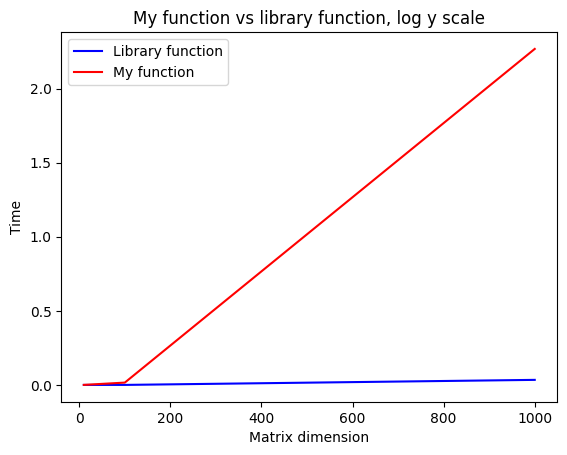

In [40]:
# Запустите этот блок кода
lib_times = []
my_times = []
dimensions = [10, 100, 1000]
for dim in dimensions:
    A = np.random.rand(dim, dim)
    res_lib = %timeit -o sla.det(A)
    lib_times.append(res_lib.best)
    res_my = %timeit -o my_det(A)
    my_times.append(res_my.best)

plt.plot(dimensions, lib_times, color='blue', label='Library function')
plt.plot(dimensions, my_times, color='red', label='My function')
plt.title('My function vs library function, log y scale')
plt.ylabel('Time')
plt.xlabel('Matrix dimension')
plt.legend()

У вас должны были получиться графики, показывающие, как растёт с ростом размерности матрицы время вычисления определителя. Поскольку они вышли не больно-то красивыми, мы нарисуем их в *логарифмическом масштабе* по оси у:

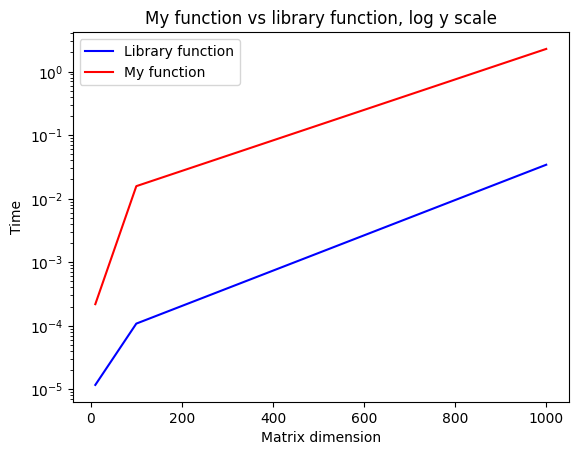

In [41]:
# Запустите этот блок кода
plt.semilogy(dimensions, lib_times, color='blue', label='Library function')
plt.semilogy(dimensions, my_times, color='red', label='My function')
plt.title('My function vs library function, log y scale')
plt.ylabel('Time')
plt.xlabel('Matrix dimension')
plt.legend()

Вы можете убедиться, что библиотечная функция работает *гораздо* быстрее.

## Часть 3. Точность

Наверняка вы уже что-то знаете про floating point arithmetics и связанные с этим трудности и понимаете, что на компьютере вычисления с вещественными числами производятся лишь с ограниченной точностью.

**Задание 3.1 [0.6 балла]** В качестве первого примера, показывающего различие между длинной арифметикой целых чисел и floating point arithmetics, предлагаем вам перемножить две пары матриц:

$$
\begin{pmatrix}
1 & 0\\
10^{20} & 1
\end{pmatrix}
\cdot
\begin{pmatrix}
10^{-20} & 1\\
0 & 1 - 10^{20}
\end{pmatrix}
$$
и
$$
\begin{pmatrix}
1. & 0.\\
10.^{20} & 1.
\end{pmatrix}
\cdot
\begin{pmatrix}
10.^{-20} & 1.\\
0. & 1. - 10.^{20}
\end{pmatrix}
$$
Во втором случае мы специально указали Питону (поставив везде десятичные точки), что хотим работать не с целыми числами, а с числами с плавающей точкой. Посмотрим, получатся ли одинаковые ответы:

In [43]:
X = np.array([[1, 0], [10 ** 20, 1]])
Y = np.array([[10 ** -20, 1], [0, 1 - 10 ** 20]])
print(X.dot(Y))
X1 = np.array([[1., 0.], [10 ** 20., 1.]])
Y1 = np.array([[10. ** -20, 1.], [0., 1. - 10 ** 20]])
print(X1.dot(Y1))

[[1e-20 1]
 [1.0 1]]
[[1.e-20 1.e+00]
 [1.e+00 0.e+00]]


И какой из них правильный?

---
1, так как вычесления с плавающей точкой не всегда точные

**Задание 3.2 [0.75 балла]** Впрочем, и с целыми числами тоже не всегда всё хорошо. Напишите функцию, генерирующую *матрицу Паскаля* заданной размерности $n$, то есть матрицу $P$, в которой $P_{ij} = C_{i+j}^i$. В этом задании нельзя пользоваться библиотечной функцией `scipy.linalg.pascal` или её аналогами из других библиотек. Обратите внимание, что использование факториалов крайне нежелательно, так как быстро приведёт к переполнению.

В этом задании вы можете использовать цикл ``for``.

In [44]:
def my_pascal(dim):

    P = np.zeros((dim, dim), dtype=int)

    for i in range(dim):
        for j in range(dim):
            if i == 0 or j == 0:
                P[i, j] = 1
            else:
                P[i, j] = P[i - 1, j] + P[i, j -1]

    return P

Чему равен её определитель? **Строго** поясните свой ответ.

----
Данную матрицу можно разложить как P = L × Lᵀ, где L — нижняя треугольная матрица с единицами на диагонали. Поскольку определитель треугольной матрицы равен произведению диагональных элементов, а у L все диагональные элементы равны 1, то det(P) = det(L) × det(Lᵀ) = 1 × 1 = 1.

А теперь вычислите определитель матрицы Паскаля $30\times30$ с помощью библиотечной функции `scipy.linalg.det`:

In [45]:
print(sla.det(my_pascal(30)))

-3.400444993542751e+51


Разница заметна невооружённым взглядом!

## Часть 4. Матричные вычисления

Вы уже видели, что использования циклов (и самописных вычислений в целом) в Питоне лучше по возможности избегать, и важно уметь находить способы делать всё библиотечными средствами.

В качестве примера рассмотрим две задачи:

**1.** Предположим, нужно вычислить суммы элементов в каждой строке матрицы `A`. Ясно, что можно написать простую функцию с двумя циклами, которая это посчитает, но так лучше не делать. Правильный способ такой:
```
A.sum(axis=1)
```
Параметр `axis=1` означает, что суммы берутся по строкам. Если вы хотите просуммировать по столбцам, укажите `axis=0`. Если вообще пропустить параметр `axis` (вызвать `A.sum()`), то функция вернёт сумму *всех* элементов матрицы.

**2.** Теперь допустим, что нам нужно каждый столбец матрицы `A` умножить на некоторое число. Более точно, пусть у нас есть (одномерный) вектор `w = np.array([w_1,...,w_n])`, и мы должны `i`-й столбец `A` умножить на число `w_i`. Опять же, это можно сделать в пару циклов, но лучше использовать операцию поэлементного умножения:
```
A * w.reshape((1,n))
```
Оператор `reshape` нужен для того, чтобы из одномерного вектора сделать вектор-строку.

Аналогично, если на числа `w_1,...,w_n` умножаются *строки* матрицы, нужно превратить `w` в вектор-столбец:
```
A * w.reshape((n,1))
```

Дальше вам будет предложено попрактиковаться в матричных вычислениях. В следующих трёх заданиях нельзя пользоваться циклами, а также конструкциями `map` и `reduce` и им подобными; вместо этого постарайтесь свести всё к матричным операциям из `numpy` (но, опять же, не `np.vectorize` или чему-то подобному). Чтобы убедиться, что получилось именно то, что нужно, пишите собственные тесты со случайными матрицами.

**Задание 4.1 [0.75 балла]** Напишите функцию `prod_and_sq_sum(A)`, вычисляющую произведение диагональных элементов, а также сумму квадратов диагональных элементов квадратной матрицы `A`.

In [46]:
def prod_and_sq_sum(A):
    n = len(A)
    p = 1
    s = 0

    for i in range(n):
        diag_el = A[i][i]
        p *= diag_el
        s += diag_el ** 2

    return p, s

**Задание 4.2 [0.75 балла]** Для матриц `A` и `B` размера $m\times n$ обозначим через $a_1,\ldots,a_n$ и $b_1,\ldots,b_n$ соответственно их столбцы; пусть также $\lambda_1, \ldots, \lambda_n$ – некоторые числа. Напишите функцию `f(A, B, lmbd, k)`, вычисляющую

$$\sum_{i=1}^{\min(k,n)}\lambda_ia_ib_i^T$$

In [47]:
def f(A, B, lmbd, k):
    n = min(len(A[0]), k)
    s = 0
    for i in range(n):
        pr = 0
        for j in range(len(A)):
            pr += A[j][i] * B[j][i]
        s += lmbd[i] * pr
    return s

**Задание 4.3 [0.75 балла]** Напишите функцию `get_diag(A,B)`, принимающую две квадратных матрицы матрицы `A` и `B` одного размера и возвращающую вектор диагональных элементов произведения `AB`, не вычисляя произведение целиком.

In [48]:
def get_diag(A, B):
    n = len(A)
    diag = []
    for i in range(n):
        el = 0
        for j in range(n):
            el += A[i][j] * B[j][i]
        diag.append(el)

    return diag

## Часть 5. Комплексные числа и геометрия

У вас уже была возможность убедиться, что многие операции над комплексными числами имеют наглядную геометрическую интерпретацию. В этом задании вам будет предложено этим воспользоваться.

В Python число $i$ (мнимая единица) обозначено через `1j`. Так, число $0,5 + 1,2i$ будет иметь вид `0.5 + 1.2 * 1j`.

При выполнении задания вы должны работать с точками плоскости как с комплексными числами. Любые преобразования должны быть реализованы с помощью операций над комплексными числами: сложения, вычитания, умножения, деления, возведения в степень и комплексного сопряжения.

**Задание 5.1 [0.5 баллов]** Напишите функцию `shrink_rotate`, которая принимает на вход:
- заданную в виде комплексного числа точку $X$, которую мы подвергаем преобразованию,
- заданную в виде комплексного числа точку $A$,
- действительный коэффициент `coef`,
- угол `alpha`, заданный в радианах

и осуществляет следующее преобразование: мы берём вектор $AX$, умножаем его на `coef`, поворачиваем вокруг точки $A$ на угол `alpha` против часовой стрелки, после чего возвращаем конец полученного вектора. Ниже (левая картинка) мы приводим иллюстрацию действия этого преобразования:

<img src="ShrinkRotate.png">

**Задание 5.2 [0.5 баллов]** Напишите функцию `shrink_rotate_conj`, которая сначала делает то же самое, что и `shrink_rotate`, а после этого отражает вектор $AY$ относительно горизонтальной прямой, проходящей через точку $A$, и возвращает точку $Y'$ (см. правую часть рисунка).

**Задание 5.3 [0.5 баллов]** Напишите функцию `geometric_inverse`, которая принимает на вход:
- заданную в виде комплексного числа точку $X$, которую мы подвергаем преобразованию,
- заданную в виде комплексного числа точку $A$,
- положительное действительное число $r$

и осуществляет инверсию точки $X$ относительно окружности с центром $A$ радиуса $r$. [Определение инверсии вы можете посмотреть здесь](https://ru.wikipedia.org/wiki/%D0%98%D0%BD%D0%B2%D0%B5%D1%80%D1%81%D0%B8%D1%8F_(%D0%B3%D0%B5%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F)).

In [49]:
import math

def shrink_rotate(x, a, coef=1., angle=0.):
    v = math.cos(angle) + 1j * math.sin(angle)
    return a + (x - a) * coef * v

    raise NotImplementedError()

def shrink_rotate_conj(x, a, coef=1., angle=0.):
    y = shrink_rotate(x, a, coef, angle)
    v = y - a
    v_c = v.real - v.imag * 1j
    return a + v_c

    raise NotImplementedError()

def geometric_inverse(x, a, r):
    v = x - a
    d = v.real * v.real + v.imag * v.imag
    v_c = v.real - v.imag * 1j
    return a + (r * r / d) * v_c

    raise NotImplementedError()

**Задание 5.4 [0.75 баллов]** Рассмотрим следующий процесс:

```
z = 0.5 + 0.*1j
max_iter = 100000
funcs = [
    (lambda t: shrink_rotate(t, 0. + 1.*1j, coef=0.5, angle=0.)),
    (lambda t: shrink_rotate(t, 1. + 0.*1j, coef=0.5, angle=0.)),
    (lambda t: shrink_rotate(t, -1. + 0.*1j, coef=0.5, angle=0.))
]

for n_iter in range(max_iter):
    n_func = np.random.choice(len(funcs))
    z = funcs[n_func](z)
```

Запустите его и нарисуйте множество точек, получающихся на итерациях начиняя с десятой.

*Указание*. Представьте квадрат $[-1,1]\times[-1,1]$ матрицей пикселей 1000x1000. Сначала все элементы матрицы положим нулями, а на каждой итерации начиная с десятой будем присваивать единицу соответствующему пикселю этой матрицы. То, что получилось, можно нарисовать с помощью функции `plt.imshow(..., cmap='gray')`. Картинку лучше сделать побольше, предварив `imshow` вызовом `plt.figure(figsize=(20, 20))`.

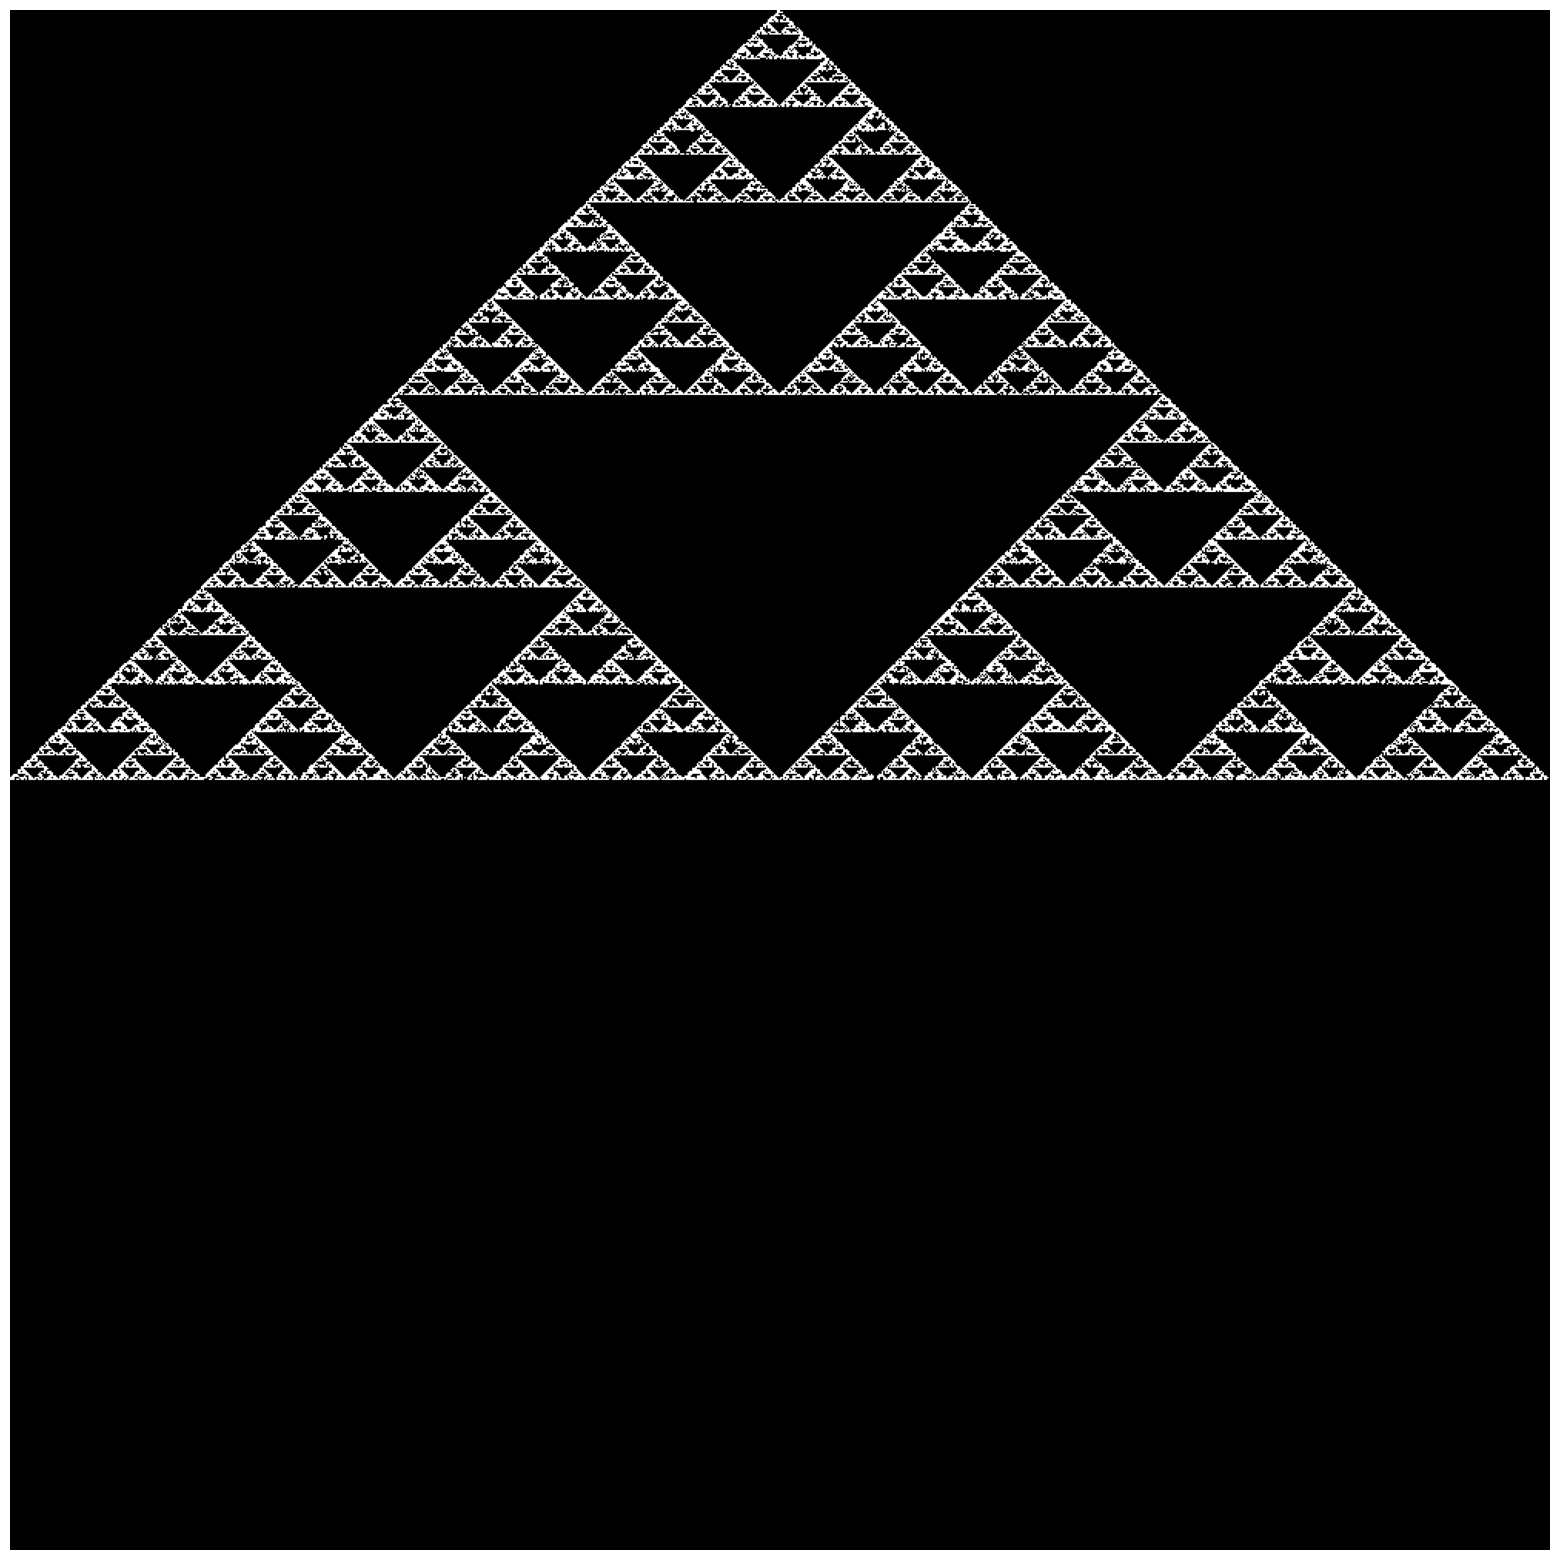

In [50]:
z = 0.5 + 0.*1j
max_iter = 100000
funcs = [
    (lambda t: shrink_rotate(t, 0. + 1.*1j, coef=0.5, angle=0.)),
    (lambda t: shrink_rotate(t, 1. + 0.*1j, coef=0.5, angle=0.)),
    (lambda t: shrink_rotate(t, -1. + 0.*1j, coef=0.5, angle=0.))
]
img = np.zeros((1000, 1000))
for n_iter in range(max_iter):
    n_func = np.random.choice(len(funcs))
    z = funcs[n_func](z)

    if n_iter >= 10:
      x = z.real
      y = z.imag
      i = int((1 - y) / 2 * 999)
      j = int((x + 1) / 2 * 999)
      if 0 <= i < 1000 and 0 <= j < 1000:
          img[i, j] = 1
plt.figure(figsize=(20, 20))
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

**Задание 5.5 [0.75 баллов]** Попробуйте объяснить, почему получается именно эта фигура.

---
Получается треугольник Серпинского потому, что каждая из трёх функций перемещает точку на половину расстояния к своей вершине треугольника: (0,1), (1,0) или (-1,0). Случайный выбор вершины на каждом шаге создаёт фрактал. Первые 10 итераций пропускаем, чтобы точка вышла на устойчивое множество. При coef=0.5 без поворотов этот процесс всегда даёт именно треугольник Серпинского — фрактал.

**Задание 5.6 [0.5 баллов]** Поэкспериментируйте с другими преобразованиями. Попробуйте найти какой-нибудь другой красиво выглядящий фрактал.

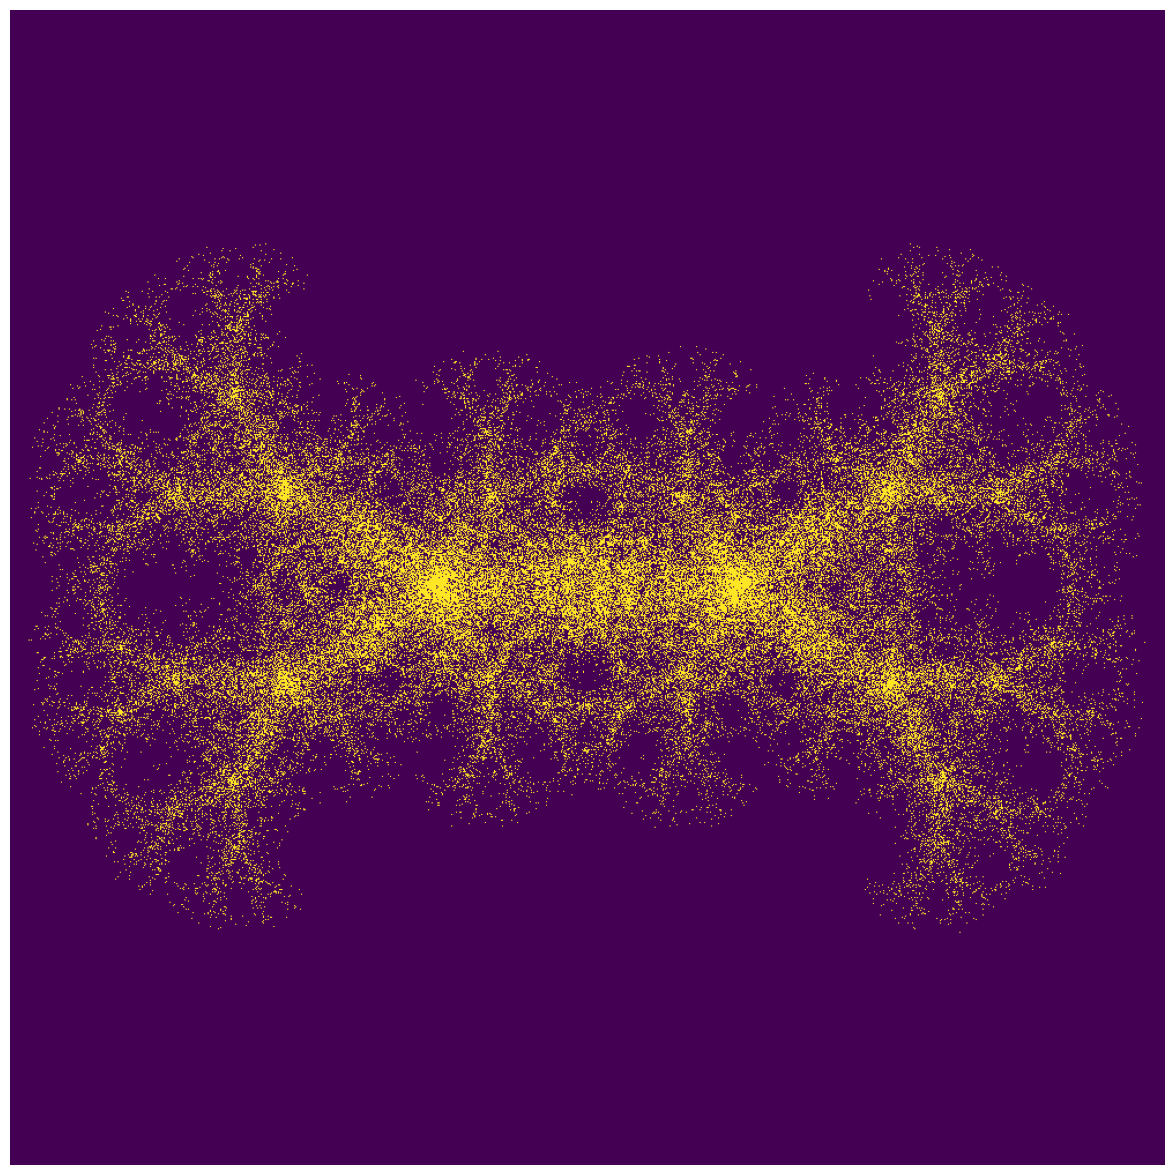

In [51]:
funcs = [
    lambda t: shrink_rotate(t, -0.5-0.5*1j, coef=0.6, angle=math.pi/6),
    lambda t: shrink_rotate(t, 0.5-0.5*1j, coef=0.6, angle=-math.pi/6),
    lambda t: shrink_rotate(t, -0.5+0.5*1j, coef=0.6, angle=-math.pi/6),
    lambda t: shrink_rotate(t, 0.5+0.5*1j, coef=0.6, angle=math.pi/6)
]

z = 0 + 0*1j
max_iter = 100000
img = np.zeros((1000, 1000))

for n_iter in range(max_iter):
    n_func = np.random.choice(len(funcs))
    z = funcs[n_func](z)

    if n_iter >= 10:
        i = int((1 - z.imag) / 2 * 999)
        j = int((z.real + 1) / 2 * 999)
        if 0 <= i < 1000 and 0 <= j < 1000:
            img[i, j] = 1

plt.figure(figsize=(15, 15))
plt.imshow(img, cmap='viridis')
plt.axis('off')
plt.show()